In [1]:
import pandas as pd
import numpy as np

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Pandas version: 3.0.6
NumPy version: 2.5.4


In [2]:
from pathlib import Path

data_path = Path("..") / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

print("Dataset path:", data_path.resolve())
print("Dataset exists:", data_path.exists())

Dataset path: C:\Users\mahim\Downloads\Machine learning project\WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset exists: True


In [3]:
import pandas as pd

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (7043, 21)


In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
print(df["Churn"].value_counts())

print("\nProportions:")
print(df["Churn"].value_counts(normalize=True).round(3))

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Proportions:
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


In [8]:
print("Original dtype:", df["TotalCharges"].dtype)

print("Blank or whitespace-only values:")
print(df["TotalCharges"].str.strip().eq("").sum())

print("\nSample values:")
print(df["TotalCharges"].head(10).tolist())

Original dtype: str
Blank or whitespace-only values:
11

Sample values:
['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.05', '3487.95']


In [9]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


# Performing Cleaning

In [10]:
# Work on a copy so the original dataset remains unchanged
df_clean = df.copy()

# Convert whitespace-only strings to missing values
df_clean["TotalCharges"] = (
    df_clean["TotalCharges"]
    .str.strip()
    .replace("", np.nan)
)

# Convert the column to numeric values
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="raise"
)

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("TotalCharges dtype:", df_clean["TotalCharges"].dtype)
print(
    "Missing TotalCharges:",
    df_clean["TotalCharges"].isna().sum()
)

Original rows: 7043
Cleaned rows: 7043
TotalCharges dtype: float64
Missing TotalCharges: 11


In [11]:
df_clean[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


In [12]:
df_clean.loc[
    df_clean["TotalCharges"].isna(),
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


# Verify the cleaning and Inspect the target

In [13]:
print("Original TotalCharges dtype:", df["TotalCharges"].dtype)
print("Cleaned TotalCharges dtype:", df_clean["TotalCharges"].dtype)

print("\nOriginal dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nOriginal churn distribution:")
print(df["Churn"].value_counts())

print("\nCleaned churn distribution:")
print(df_clean["Churn"].value_counts())

print("\nMissing values in cleaned dataset:")
print(
    df_clean.isna().sum()[df_clean.isna().sum() > 0]
)

Original TotalCharges dtype: str
Cleaned TotalCharges dtype: float64

Original dataset shape: (7043, 21)
Cleaned dataset shape: (7043, 21)

Original churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Cleaned churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Missing values in cleaned dataset:
TotalCharges    11
dtype: int64


# Visualize the churn distribution

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

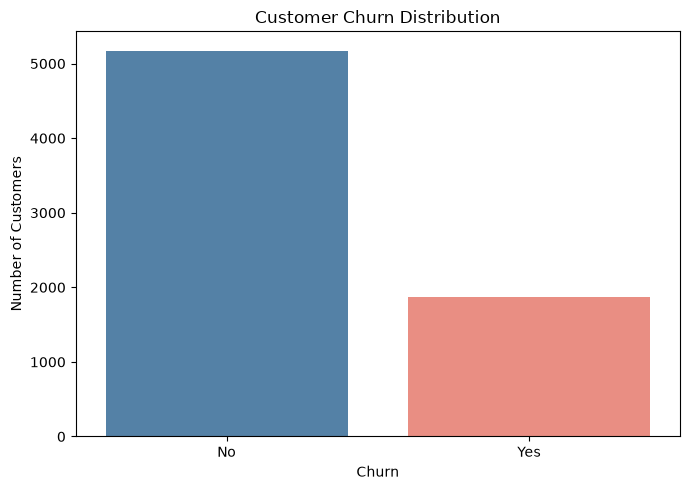

In [15]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="Churn",
    hue="Churn",
    order=["No", "Yes"],
    hue_order=["No", "Yes"],
    palette={"No": "steelblue", "Yes": "salmon"},
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

# Explore churn by customer tenure

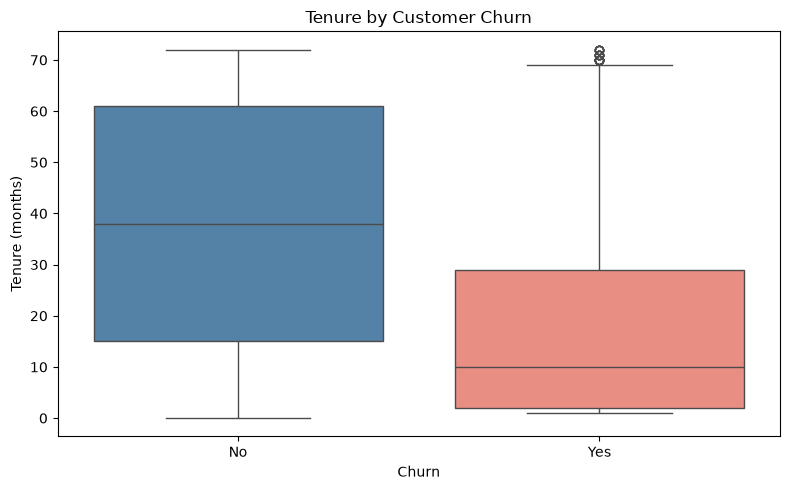

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="tenure",
    hue="Churn",
    order=["No", "Yes"],
    hue_order=["No", "Yes"],
    palette={"No": "steelblue", "Yes": "salmon"},
    legend=False
)

plt.title("Tenure by Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (months)")

plt.tight_layout()
plt.show()

In [17]:
df_clean.groupby("Churn", observed=True)["tenure"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


# Explore churn by contract type

In [18]:
df_clean["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [19]:
contract_churn = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
) * 100

contract_churn = contract_churn.reindex(
    columns=["No", "Yes"]
)

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


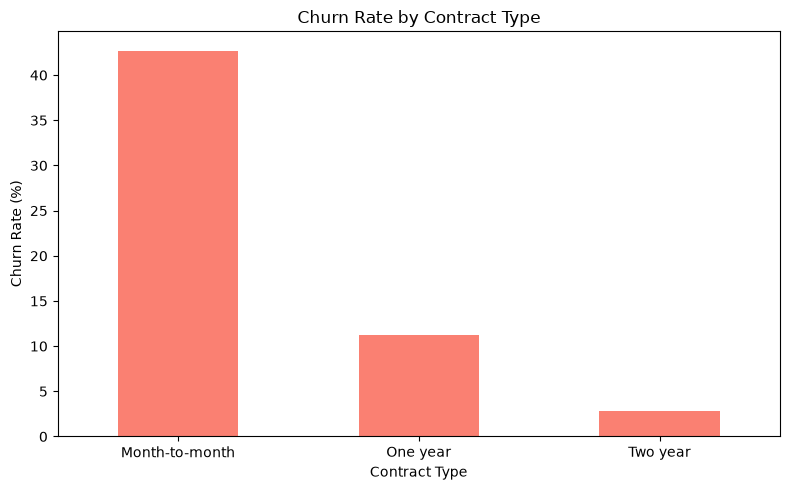

In [20]:
contract_churn["Yes"].plot(
    kind="bar",
    color="salmon",
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Monthly Charges

In [21]:
df_clean.groupby("Churn", observed=True)["MonthlyCharges"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


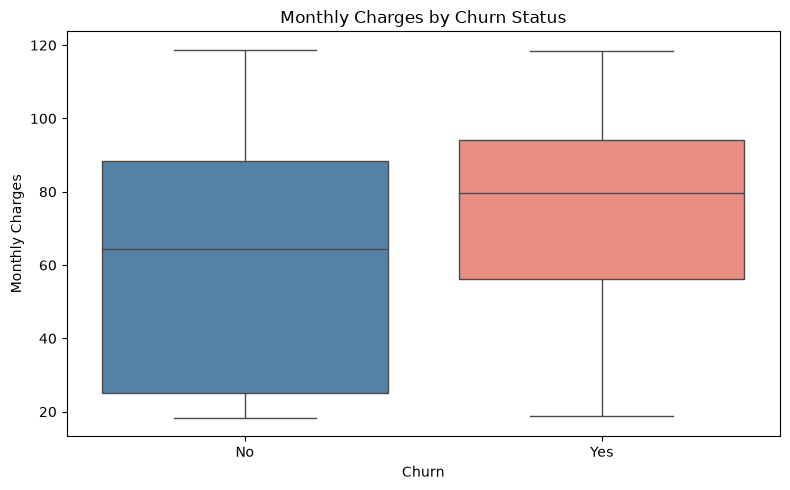

In [22]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    order=["No", "Yes"],
    palette={"No": "steelblue", "Yes": "salmon"},
    legend=False
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

# Payment methods

In [23]:
df_clean["PaymentMethod"].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [24]:
payment_churn = pd.crosstab(
    df_clean["PaymentMethod"],
    df_clean["Churn"],
    normalize="index"
) * 100

payment_churn = payment_churn.reindex(
    columns=["No", "Yes"]
)

print(payment_churn.round(2))

Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


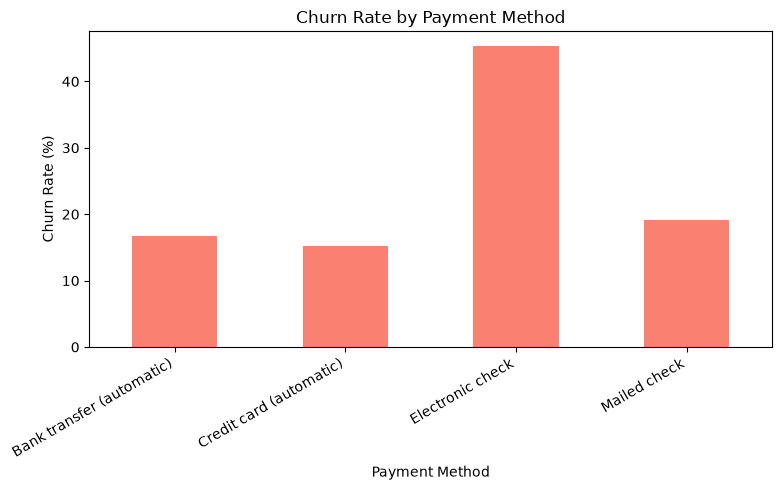

In [25]:
payment_churn["Yes"].plot(
    kind="bar",
    color="salmon",
    figsize=(8, 5)
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Internet Service Provider

In [26]:
df_clean["InternetService"].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [27]:
Internet_churn = pd.crosstab(
    df_clean["InternetService"],
    df_clean["Churn"],
    normalize="index"
) * 100

Internet_churn = Internet_churn.reindex(
    columns=["No", "Yes"]
)

print(Internet_churn.round(2))

Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


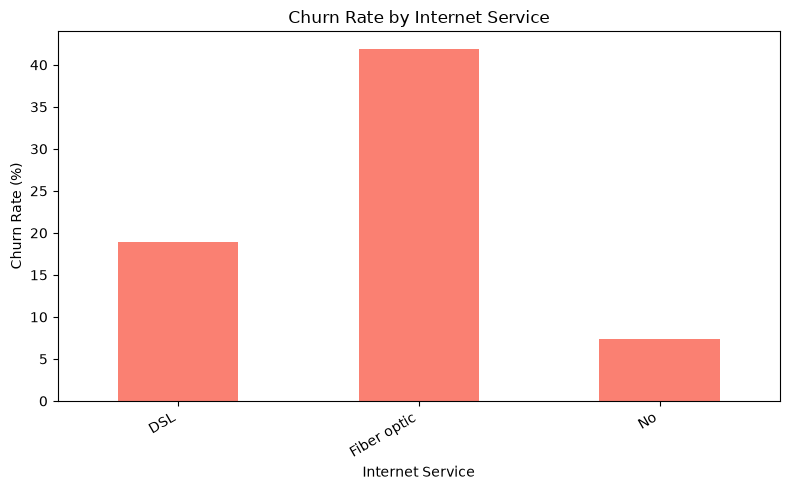

In [28]:
Internet_churn["Yes"].plot(
    kind="bar",
    color="salmon",
    figsize=(8, 5)
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [29]:
categorical_columns = df_clean.select_dtypes(
    include=["object", "str", "category"]
).columns

for column in categorical_columns:
    print(f"\n{column}")
    print(df_clean[column].value_counts(dropna=False))


customerID
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup
OnlineBackup
No                     3088
Yes                    2429


# Prepare Feature and Target

In [30]:
# Separate the target from the input features
X = df_clean.drop(columns=["customerID", "Churn"])
y = df_clean["Churn"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nFeature columns:")
print(X.columns.tolist())

print("\nMissing values in features:")
print(X.isna().sum()[X.isna().sum() > 0])

Feature matrix shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Missing values in features:
TotalCharges    11
dtype: int64


# Split the training and the test data

In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training features: (5634, 19)
Test features: (1409, 19)

Training target distribution:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Test target distribution:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


# Build the preprocessing pipeline

In [32]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Number of numeric features:", len(numeric_features))
print(numeric_features)

print("\nNumber of categorical features:", len(categorical_features))
print(categorical_features)

Number of numeric features: 4
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Number of categorical features: 15
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [33]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

print("Numerical preprocessing pipeline created:")
print(numeric_transformer)


Numerical preprocessing pipeline created:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])


In [34]:
from sklearn.preprocessing import OneHotEncoder

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

print("Categorical preprocessing pipeline created:")
print(categorical_transformer)

Categorical preprocessing pipeline created:
Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(handle_unknown='ignore'))])


In [35]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Combined preprocessor created:")
print(preprocessor)

Combined preprocessor created:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['SeniorCitizen', 'tenure', 'MonthlyCharges',
                                  'TotalCharges']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['gender', 'Partner', 'Dependents',
                                  'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                  

In [36]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline

baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DummyClassifier(strategy="most_frequent"))
    ]
)

print("Baseline model pipeline created:")
print(baseline_model)

Baseline model pipeline created:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('oneh

In [37]:

from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print("Logistic regression pipeline created:")
print(logistic_model)


Logistic regression pipeline created:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  (

# Train the models

In [38]:

# Train the baseline model
baseline_model.fit(X_train, y_train)

# Train the logistic regression model
logistic_model.fit(X_train, y_train)

print("Both models trained successfully.")


Both models trained successfully.


# Evaluate initial training performance

In [39]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Baseline": baseline_model,
    "Logistic Regression": logistic_model
}

for name, model in models.items():
    y_train_pred = model.predict(X_train)

    print(f"\n{name}")
    print("-" * len(name))
    print(f"Accuracy:  {accuracy_score(y_train, y_train_pred):.4f}")
    print(f"Precision: {precision_score(y_train, y_train_pred, pos_label='Yes', zero_division=0):.4f}")
    print(f"Recall:    {recall_score(y_train, y_train_pred, pos_label='Yes', zero_division=0):.4f}")
    print(f"F1-score:  {f1_score(y_train, y_train_pred, pos_label='Yes', zero_division=0):.4f}")



Baseline
--------
Accuracy:  0.7346
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000

Logistic Regression
-------------------
Accuracy:  0.8060
Precision: 0.6616
Recall:    0.5505
F1-score:  0.6009


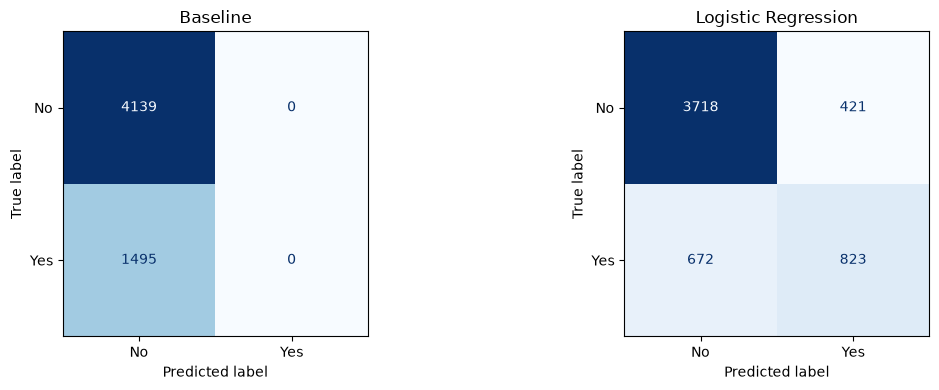

In [40]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, model) in zip(axes, models.items()):
    y_train_pred = model.predict(X_train)

    cm = confusion_matrix(
        y_train,
        y_train_pred,
        labels=["No", "Yes"]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No", "Yes"]
    )

    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()


In [41]:

from sklearn.metrics import roc_auc_score

for name, model in models.items():
    y_train_proba = model.predict_proba(X_train)[:, 1]

    # Locate the probability column corresponding to "Yes"
    yes_index = list(
        model.named_steps["classifier"].classes_
    ).index("Yes")

    y_train_proba = model.predict_proba(X_train)[:, yes_index]

    auc = roc_auc_score(
        (y_train == "Yes").astype(int),
        y_train_proba
    )

    print(f"{name} ROC-AUC: {auc:.4f}")


Baseline ROC-AUC: 0.5000
Logistic Regression ROC-AUC: 0.8493


In [42]:

from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for name, model in models.items():
    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    print(f"\n{name}")
    print("Fold ROC-AUC scores:", cv_scores.round(4))
    print(f"Mean ROC-AUC: {cv_scores.mean():.4f}")
    print(f"Standard deviation: {cv_scores.std():.4f}")



Baseline
Fold ROC-AUC scores: [0.5 0.5 0.5 0.5 0.5]
Mean ROC-AUC: 0.5000
Standard deviation: 0.0000

Logistic Regression
Fold ROC-AUC scores: [0.8479 0.8252 0.8419 0.8629 0.8529]
Mean ROC-AUC: 0.8461
Standard deviation: 0.0125


# Using other model: Decision Tree and Random Forest

In [43]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

candidate_models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", DecisionTreeClassifier(random_state=42))
        ]
    ),
    "Random Forest": Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", RandomForestClassifier(
                n_estimators=100,
                random_state=42,
                n_jobs=1
            ))
        ]
    )
}

cv_results = {}

for name, model in candidate_models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    cv_results[name] = scores

    print(f"\n{name}")
    print("Fold ROC-AUC:", scores.round(4))
    print(f"Mean ROC-AUC: {scores.mean():.4f}")
    print(f"Standard deviation: {scores.std():.4f}")



Logistic Regression
Fold ROC-AUC: [0.8479 0.8252 0.8419 0.8629 0.8529]
Mean ROC-AUC: 0.8461
Standard deviation: 0.0125

Decision Tree
Fold ROC-AUC: [0.6472 0.6454 0.6721 0.6742 0.6526]
Mean ROC-AUC: 0.6583
Standard deviation: 0.0124

Random Forest
Fold ROC-AUC: [0.8128 0.8015 0.8235 0.815  0.8384]
Mean ROC-AUC: 0.8182
Standard deviation: 0.0123


# Tune logistic regression with GridSearchCV

In [44]:

from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print(f"Best mean CV ROC-AUC: {grid_search.best_score_:.4f}")

print("\nResults for each C value:")

for mean_score, params in zip(
    grid_search.cv_results_["mean_test_score"],
    grid_search.cv_results_["params"]
):
    print(f"C = {params['classifier__C']:<6} ROC-AUC = {mean_score:.4f}")


Best parameters: {'classifier__C': 10}
Best mean CV ROC-AUC: 0.8463

Results for each C value:
C = 0.01   ROC-AUC = 0.8435
C = 0.1    ROC-AUC = 0.8455
C = 1      ROC-AUC = 0.8461
C = 10     ROC-AUC = 0.8463
C = 100    ROC-AUC = 0.8463


In [45]:

from sklearn.model_selection import cross_val_predict

best_logistic_model = grid_search.best_estimator_

y_train_proba_oof = cross_val_predict(
    best_logistic_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

yes_index = list(
    best_logistic_model.named_steps["classifier"].classes_
).index("Yes")

y_train_proba_oof = y_train_proba_oof[:, yes_index]

print("Out-of-fold probabilities created.")
print("Number of probabilities:", len(y_train_proba_oof))
print("Minimum probability:", round(y_train_proba_oof.min(), 4))
print("Maximum probability:", round(y_train_proba_oof.max(), 4))


Out-of-fold probabilities created.
Number of probabilities: 5634
Minimum probability: 0.0011
Maximum probability: 0.8638


In [46]:

import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

threshold_results = []

y_train_binary = (y_train == "Yes").astype(int)

for threshold in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    y_pred_threshold = (
        y_train_proba_oof >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_train_binary, y_pred_threshold
        ),
        "Precision": precision_score(
            y_train_binary, y_pred_threshold,
            zero_division=0
        ),
        "Recall": recall_score(
            y_train_binary, y_pred_threshold,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_train_binary, y_pred_threshold,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4).to_string(index=False))


 Threshold  Accuracy  Precision  Recall  F1-score
       0.2    0.7102     0.4744  0.8569    0.6107
       0.3    0.7646     0.5397  0.7686    0.6341
       0.4    0.7897     0.5929  0.6615    0.6254
       0.5    0.8037     0.6555  0.5485    0.5972
       0.6    0.7975     0.7117  0.3980    0.5105
       0.7    0.7748     0.7770  0.2120    0.3332


Confusion matrix at threshold 0.30
Rows = actual; columns = predicted
[[3159  980]
 [ 346 1149]]


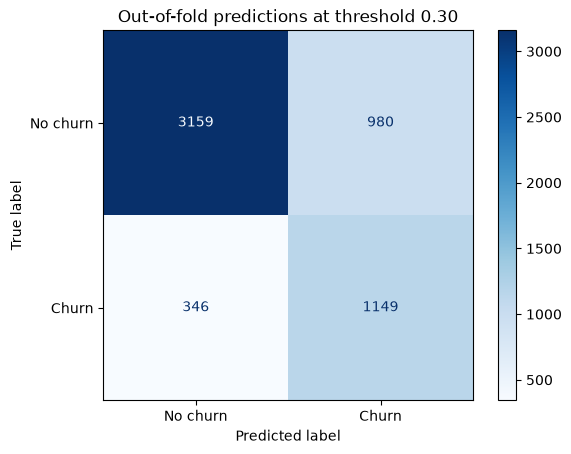

In [47]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

selected_threshold = 0.30

y_train_pred_030 = (
    y_train_proba_oof >= selected_threshold
).astype(int)

cm_030 = confusion_matrix(
    y_train_binary,
    y_train_pred_030,
    labels=[0, 1]
)

print("Confusion matrix at threshold 0.30")
print("Rows = actual; columns = predicted")
print(cm_030)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_030,
    display_labels=["No churn", "Churn"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Out-of-fold predictions at threshold 0.30")
plt.show()


In [48]:

print("Best model:")
print(best_logistic_model)

print("\nBest cross-validation ROC-AUC:")
print(round(grid_search.best_score_, 4))

print("\nSelected threshold:", selected_threshold)


Best model:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                

Final Test Results
Threshold: 0.30
Accuracy:  0.7488
Precision: 0.5185
Recall:    0.7513
F1-score:  0.6135
ROC-AUC:   0.8412

Classification Report
              precision    recall  f1-score   support

    No churn       0.89      0.75      0.81      1035
       Churn       0.52      0.75      0.61       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.79      0.75      0.76      1409



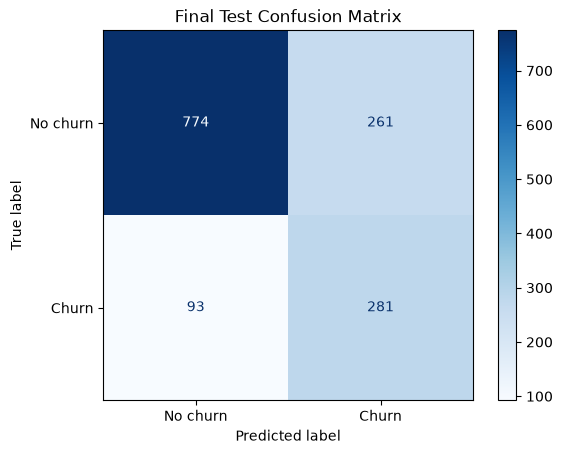

In [49]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict churn probabilities on the untouched test set
yes_index = list(
    best_logistic_model.named_steps["classifier"].classes_
).index("Yes")

y_test_proba = best_logistic_model.predict_proba(X_test)[:, yes_index]

# Apply the threshold selected using training-only validation
y_test_pred = (
    y_test_proba >= selected_threshold
).astype(int)

# Convert actual labels to 0 = No, 1 = Yes
y_test_binary = (y_test == "Yes").astype(int)

# Calculate final test metrics
print("Final Test Results")
print("=" * 40)
print(f"Threshold: {selected_threshold:.2f}")
print(f"Accuracy:  {accuracy_score(y_test_binary, y_test_pred):.4f}")
print(f"Precision: {precision_score(y_test_binary, y_test_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test_binary, y_test_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test_binary, y_test_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test_binary, y_test_proba):.4f}")

print("\nClassification Report")
print(classification_report(
    y_test_binary,
    y_test_pred,
    target_names=["No churn", "Churn"],
    zero_division=0
))

# Plot the test confusion matrix
cm_test = confusion_matrix(
    y_test_binary,
    y_test_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=["No churn", "Churn"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Final Test Confusion Matrix")
plt.show()


In [50]:

import pandas as pd
import numpy as np

# Get the fitted preprocessing and classifier steps
fitted_preprocessor = best_logistic_model.named_steps["preprocessor"]
fitted_classifier = best_logistic_model.named_steps["classifier"]

# Retrieve feature names after imputation, scaling, and encoding
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract logistic regression coefficients
coefficients = fitted_classifier.coef_[0]

# Create a table of features and their coefficients
coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by coefficient
coefficient_df = coefficient_df.sort_values(
    by="Coefficient",
    ascending=False
).reset_index(drop=True)

print("Number of transformed features:", len(feature_names))
print("\nTop 10 positive coefficients:")
print(coefficient_df.head(10).to_string(index=False))

print("\nTop 10 negative coefficients:")
print(
    coefficient_df.tail(10)
    .sort_values("Coefficient")
    .to_string(index=False)
)


Number of transformed features: 45

Top 10 positive coefficients:
                            Feature  Coefficient
   cat__InternetService_Fiber optic     1.299306
                  num__TotalCharges     0.576268
       cat__Contract_Month-to-month     0.540791
           cat__StreamingMovies_Yes     0.517568
               cat__StreamingTV_Yes     0.516811
             cat__MultipleLines_Yes     0.332281
          cat__DeviceProtection_Yes     0.220183
cat__PaymentMethod_Electronic check     0.167273
              cat__OnlineBackup_Yes     0.152082
             cat__OnlineSecurity_No     0.127642

Top 10 negative coefficients:
                                  Feature  Coefficient
                      num__MonthlyCharges    -1.993468
                              num__tenure    -1.298987
                 cat__InternetService_DSL    -1.143193
                   cat__Contract_Two year    -0.823077
     cat__StreamingTV_No internet service    -0.595026
 cat__StreamingMovies_No internet 

In [51]:

# Calculate odds ratios for the strongest coefficients

coefficient_df["OddsRatio"] = np.exp(
    coefficient_df["Coefficient"]
)

top_positive = coefficient_df.nlargest(
    10, "Coefficient"
).copy()

top_negative = coefficient_df.nsmallest(
    10, "Coefficient"
).copy()

print("Top 10 positive coefficients with odds ratios:")
print(
    top_positive[
        ["Feature", "Coefficient", "OddsRatio"]
    ].round(4).to_string(index=False)
)

print("\nTop 10 negative coefficients with odds ratios:")
print(
    top_negative[
        ["Feature", "Coefficient", "OddsRatio"]
    ].round(4).to_string(index=False)
)


Top 10 positive coefficients with odds ratios:
                            Feature  Coefficient  OddsRatio
   cat__InternetService_Fiber optic       1.2993     3.6668
                  num__TotalCharges       0.5763     1.7794
       cat__Contract_Month-to-month       0.5408     1.7174
           cat__StreamingMovies_Yes       0.5176     1.6779
               cat__StreamingTV_Yes       0.5168     1.6767
             cat__MultipleLines_Yes       0.3323     1.3941
          cat__DeviceProtection_Yes       0.2202     1.2463
cat__PaymentMethod_Electronic check       0.1673     1.1821
              cat__OnlineBackup_Yes       0.1521     1.1643
             cat__OnlineSecurity_No       0.1276     1.1361

Top 10 negative coefficients with odds ratios:
                                 Feature  Coefficient  OddsRatio
                     num__MonthlyCharges      -1.9935     0.1362
                             num__tenure      -1.2990     0.2728
                cat__InternetService_DSL      -1.1

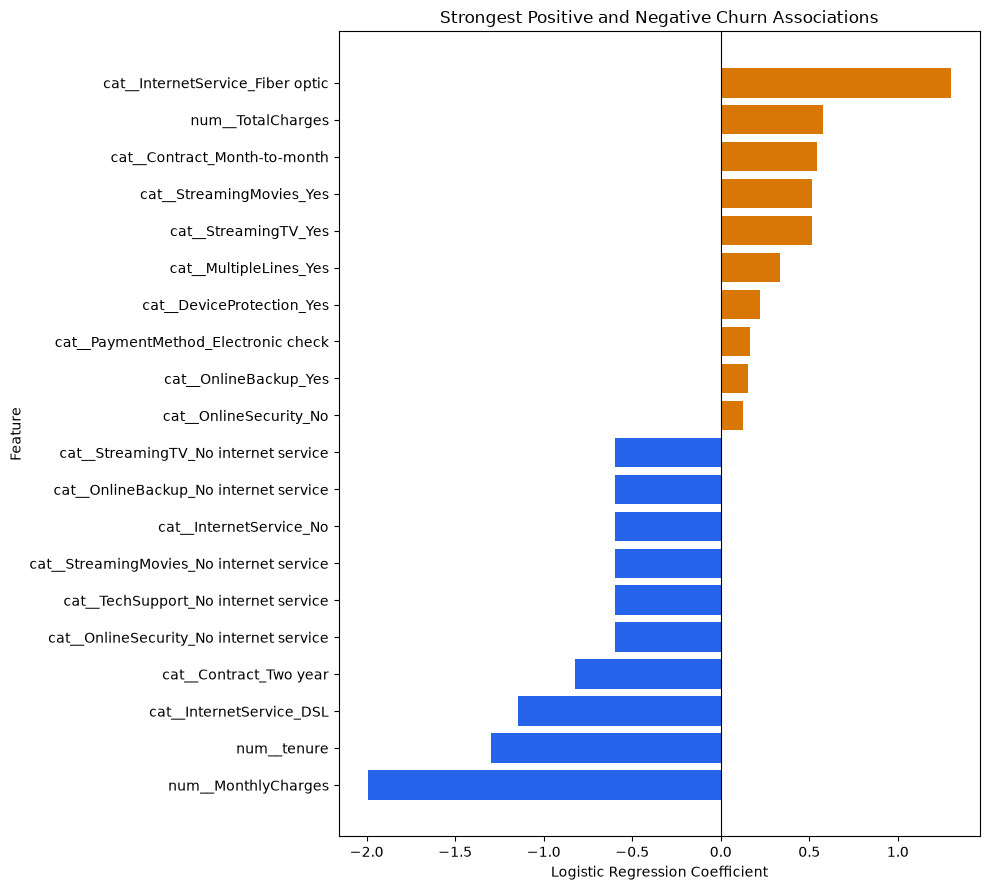

In [52]:

import matplotlib.pyplot as plt

# Select the strongest positive and negative coefficients
plot_df = pd.concat([
    coefficient_df.nlargest(10, "Coefficient"),
    coefficient_df.nsmallest(10, "Coefficient")
]).sort_values("Coefficient")

colors = [
    "#D97706" if value > 0 else "#2563EB"
    for value in plot_df["Coefficient"]
]

plt.figure(figsize=(10, 9))

plt.barh(
    plot_df["Feature"],
    plot_df["Coefficient"],
    color=colors
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Strongest Positive and Negative Churn Associations")
plt.tight_layout()
plt.show()


# Testing

In [53]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

model_path = PROJECT_ROOT / "models" / "logistic_regression_pipeline.joblib"

print("Project root:", PROJECT_ROOT)
print("Model path:", model_path)
print("Models folder exists:", model_path.parent.exists())
print("Model file exists:", model_path.exists())

Project root: c:\Users\mahim\Downloads\Machine learning project
Model path: c:\Users\mahim\Downloads\Machine learning project\models\logistic_regression_pipeline.joblib
Models folder exists: True
Model file exists: True


In [54]:
import importlib
import src.train

importlib.reload(src.train)

from src.train import prepare_features, train_model

print("prepare_features:", callable(prepare_features))
print("train_model:", callable(train_model))

prepare_features: True
train_model: True


In [55]:
from sklearn.model_selection import train_test_split

from src.data import load_data
from src.train import prepare_features

df = load_data()
X, y = prepare_features(df)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)

Training features: (5634, 19)
Test features: (1409, 19)


In [56]:
from src.train import train_model

model = train_model(
    X_train=X_train,
    y_train=y_train,
    C=10,
    model_path=model_path,
)

print("Model trained and saved:", model_path)
print("File exists:", model_path.is_file())

Model trained and saved: c:\Users\mahim\Downloads\Machine learning project\models\logistic_regression_pipeline.joblib
File exists: True


In [57]:
from src.predict import predict_churn

sample_customer = X_train.iloc[[0]].copy()

prediction = predict_churn(
    customer_data=sample_customer,
    model_path=model_path,
)

print(prediction)

      churn_probability  predicted_churn predicted_label
3738           0.344094                1             Yes


In [58]:
batch = X_train.iloc[:5].copy()

batch_predictions = predict_churn(
    customer_data=batch,
    model_path=model_path,
)

print(batch_predictions)
print("Number of predictions:", len(batch_predictions))

      churn_probability  predicted_churn predicted_label
3738           0.344094                1             Yes
3151           0.287625                0              No
4860           0.042731                0              No
3867           0.096378                0              No
3810           0.387491                1             Yes
Number of predictions: 5
